# How Much Does the Sun Warm the Air? (simple estimate)

A rough, untuned estimate of how much solar radiation warms outdoor air, meant as a starting point for greenhouse estimates.

Run `weather_station_analysis.ipynb` first. This notebook reads `output/combined_weather_data.csv` and the hourly rain file.

**Expected folder layout** (run the notebooks from `senior_design/`):
```
senior_design/
├── summer_data/        1-minute station files (.xlsx)
├── rain_data/          hourly precipitation file (.xlsx)
├── output/             created by weather_station_analysis.ipynb
│   ├── combined_weather_data.csv
│   ├── tuning/         solar_temp_tuning.ipynb results
│   └── sun_warming/    sun_warming_estimate.ipynb results
├── weather_station_analysis.ipynb
├── solar_temp_tuning.ipynb
└── sun_warming_estimate.ipynb
```

**Rules (no parameter tuning):**
1. **Rain days removed.** Any day with rain recorded is dropped completely.
2. **Hard cutoff time.** Using the dry days, the average temperature curve for the day is built and the time where it stops rising (average change turns negative) becomes one fixed cutoff for every day. Only data from first sun to that cutoff is used.
3. **No lag, no cooling term.**

**Two fits:**
- **Fit A, rate vs strength:** warming rate (°C/hr) in each block vs mean solar radiation (W/m²) in that block.
- **Fit B, total rise vs total energy (recommended):** temperature rise since first sun (°C) vs solar energy received since first sun (MJ/m²). Air warms from energy built up over the morning, not from the sun's strength at one moment, so this is the steadier relationship.

## 1. Settings

In [ ]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

COMBINED_CSV    = "output/combined_weather_data.csv"
RAIN_DIR        = "./rain_data"   # folder with the hourly precipitation file
RAIN_FILE       = sorted(glob.glob(os.path.join(RAIN_DIR, "*.xls*")) + glob.glob(os.path.join(RAIN_DIR, "*.csv")))[0]
RAIN_LABEL      = "start"        # same meaning as in the main notebook
OUT_DIR         = "output/sun_warming"

SOLAR_START     = 0              # W/m2; first minute above this = first sun
BLOCK           = "30min"        # block length for Fit A and sampling for Fit B
CUTOFF_OVERRIDE = None           # e.g. "14:30" to force a cutoff time instead of computing it

TIME, TEMP, SOLAR = "time", "temp_C", "solar_Wm2"
os.makedirs(OUT_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
SOLAR_COLOR, TEMP_COLOR, DARK = "#e0a100", "#c8553d", "#333333"


## 2. Load data and remove rain days

In [2]:
data = pd.read_csv(COMBINED_CSV, parse_dates=[TIME], index_col=TIME)
step = data.index.to_series().diff().mode().iloc[0]
data = data.asfreq(step)
data["date"] = data.index.normalize()

raw = pd.read_excel(RAIN_FILE, header=None) if RAIN_FILE.endswith(("xlsx", "xls")) else pd.read_csv(RAIN_FILE, header=None)
hdr = next(i for i, v in raw.iloc[:, 0].items() if isinstance(v, str) and v.strip().lower().startswith("date"))
rain = raw.iloc[hdr + 1:, :2].copy()
rain.columns = [TIME, "rain_cm"]
rain[TIME] = pd.to_datetime(rain[TIME], errors="coerce")
rain["rain_cm"] = pd.to_numeric(rain["rain_cm"], errors="coerce")
rain = rain.dropna(subset=[TIME])
rain["hour_start"] = rain[TIME] + (pd.Timedelta(0) if RAIN_LABEL == "start" else -pd.Timedelta(hours=1))
rain_days = set(rain.loc[rain["rain_cm"] > 0, "hour_start"].dt.normalize())

all_days = sorted(data.dropna(subset=[TEMP])["date"].unique())
dry_days = [d for d in all_days if d not in rain_days]
dry = data[data["date"].isin(dry_days)]
print(f"Days with data: {len(all_days)}   rain days removed: {len(all_days) - len(dry_days)}   dry days kept: {len(dry_days)}")

Days with data: 91   rain days removed: 30   dry days kept: 61


## 3. Hard cutoff: when does the average day stop warming?

All dry days are stacked by time of day and averaged. The cutoff is the time the average temperature peaks, which is where its change turns from positive to negative.

Cutoff time: 16:08  (average dry-day temperature peaks here)


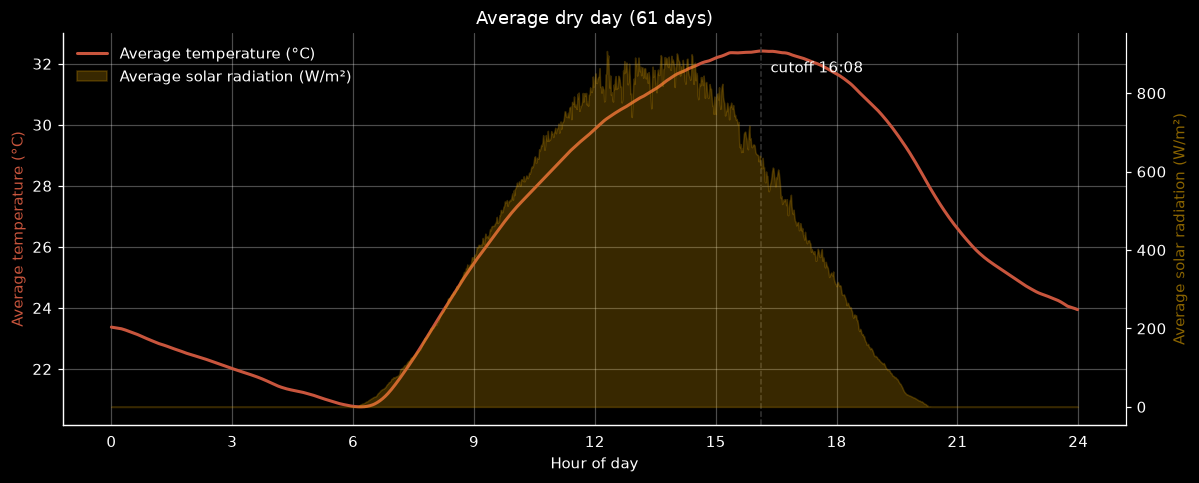

In [3]:
tod = dry.index.hour * 60 + dry.index.minute                       # minute of the day
avg_day = dry.groupby(tod)[TEMP].mean()
avg_day_smooth = avg_day.rolling(31, center=True, min_periods=1).mean()   # 30-min smoothing
avg_solar = dry.groupby(tod)[SOLAR].mean()

if CUTOFF_OVERRIDE:
    h, m = map(int, CUTOFF_OVERRIDE.split(":"))
    cutoff_min = h * 60 + m
else:
    cutoff_min = int(avg_day_smooth.idxmax())
cutoff_str = f"{cutoff_min // 60:02d}:{cutoff_min % 60:02d}"
print(f"Cutoff time: {cutoff_str}  (average dry-day temperature peaks here)")

fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax2 = ax1.twinx()
hours = avg_day.index / 60
ax2.fill_between(hours, avg_solar.values, color=SOLAR_COLOR, alpha=0.25, label="Average solar radiation (W/m²)")
ax1.plot(hours, avg_day_smooth.values, color=TEMP_COLOR, lw=2, label="Average temperature (°C)")
ax1.axvline(cutoff_min / 60, color=DARK, ls="--", lw=1)
ax1.annotate(f"cutoff {cutoff_str}", (cutoff_min / 60, avg_day_smooth.max()), xytext=(6, -14), textcoords="offset points")
ax1.set_xlabel("Hour of day"); ax1.set_xticks(range(0, 25, 3))
ax1.set_ylabel("Average temperature (°C)", color=TEMP_COLOR)
ax2.set_ylabel("Average solar radiation (W/m²)", color="#8a6400"); ax2.grid(False)
ax2.spines["right"].set_visible(True)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", frameon=False)
ax1.set_title(f"Average dry day ({len(dry_days)} days)")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "average_day_cutoff.png"), dpi=200, bbox_inches="tight")
plt.show()

## 4. Build the warming-period data

For each dry day, keep data from first sun to the cutoff. For every minute, compute:
- temperature rise since first sun (°C)
- solar energy received since first sun (MJ/m²) = sum of W/m² × seconds ÷ 1,000,000

In [4]:
pieces = []
for d in dry_days:
    g = dry[dry["date"] == d]
    sunny = g.index[g[SOLAR] > SOLAR_START]
    if len(sunny) == 0:
        continue
    start, end = sunny[0], d + pd.Timedelta(minutes=cutoff_min)
    w = g.loc[start:end, [TEMP, SOLAR]].copy()
    t0 = w[TEMP].dropna()
    if len(t0) < 60 or start >= end:
        continue
    w["energy_MJ_m2"] = w[SOLAR].fillna(0).cumsum() * step.total_seconds() / 1e6
    w["rise_C"] = w[TEMP] - t0.iloc[0]
    w["date"] = d
    pieces.append(w)
warm = pd.concat(pieces)
print(f"Days used: {warm['date'].nunique()}   minutes: {len(warm):,}")

Days used: 61   minutes: 35,230


## 5. Fit A: warming rate vs solar strength (your original question)

Same idea as the main notebook, but with rain days removed and the hard cutoff applied. If this slope comes out flat or negative, that is expected: in the morning the air warms fastest around 8 to 10 am when the sun is still low, then slows near the peak when the sun is strongest. This fit is kept for comparison.

In [5]:
def block_rate(g):
    t = g[TEMP].dropna()
    if len(t) < 0.8 * (pd.Timedelta(BLOCK) / step):
        return pd.Series({"solar": np.nan, "rate": np.nan})
    hrs = (t.index[-1] - t.index[0]).total_seconds() / 3600
    return pd.Series({"solar": g[SOLAR].mean(), "rate": (t.iloc[-1] - t.iloc[0]) / hrs})

blocks_A = warm.groupby(["date", pd.Grouper(freq=BLOCK)])[[TEMP, SOLAR]].apply(block_rate).dropna()
fitA = stats.linregress(blocks_A["solar"], blocks_A["rate"])
print(f"Fit A: rate (°C/hr) = {fitA.slope:.5f} × solar (W/m²) {fitA.intercept:+.3f}   R² = {fitA.rvalue**2:.3f}   n = {len(blocks_A)}")

Fit A: rate (°C/hr) = -0.00108 × solar (W/m²) +1.896   R² = 0.067   n = 1133


## 6. Fit B: total rise vs total solar energy (recommended)

Sampled every `BLOCK` so neighbouring minutes do not count as separate evidence. Two versions:
- **B1, within the morning:** every sample from every dry day
- **B2, one point per day:** the full rise from first sun to the cutoff vs that day's energy up to the cutoff

In [6]:
samples_B = (warm.groupby(["date", pd.Grouper(freq=BLOCK)])[["rise_C", "energy_MJ_m2"]].last()
             .dropna(subset=["rise_C", "energy_MJ_m2"]))
samples_B = samples_B[samples_B["energy_MJ_m2"] > 0]
fitB = stats.linregress(samples_B["energy_MJ_m2"], samples_B["rise_C"])

per_day = warm.groupby("date").agg(energy_MJ_m2=("energy_MJ_m2", "max"),
                                   rise_C=("rise_C", lambda s: s.dropna().iloc[-1]),
                                   max_rise_C=("rise_C", "max"))
fitB2 = stats.linregress(per_day["energy_MJ_m2"], per_day["rise_C"]) if len(per_day) >= 3 else None

print(f"Fit B1 (within morning): rise (°C) = {fitB.slope:.3f} × energy (MJ/m²) {fitB.intercept:+.2f}"
      f"   R² = {fitB.rvalue**2:.3f}   n = {len(samples_B)}")
if fitB2:
    print(f"Fit B2 (one per day):    rise (°C) = {fitB2.slope:.3f} × energy (MJ/m²) {fitB2.intercept:+.2f}"
          f"   R² = {fitB2.rvalue**2:.3f}   n = {len(per_day)} days")
print(f"\nRough answer: each MJ/m² of sunlight raised outdoor air about {fitB.slope:.2f} °C during the morning warm-up.")
print(f"1 MJ/m² is roughly one hour of 280 W/m² sun, or about 17 minutes of full summer sun (1000 W/m²).")

Fit B1 (within morning): rise (°C) = 0.510 × energy (MJ/m²) +3.32   R² = 0.652   n = 1248
Fit B2 (one per day):    rise (°C) = 0.669 × energy (MJ/m²) -1.85   R² = 0.428   n = 61 days

Rough answer: each MJ/m² of sunlight raised outdoor air about 0.51 °C during the morning warm-up.
1 MJ/m² is roughly one hour of 280 W/m² sun, or about 17 minutes of full summer sun (1000 W/m²).


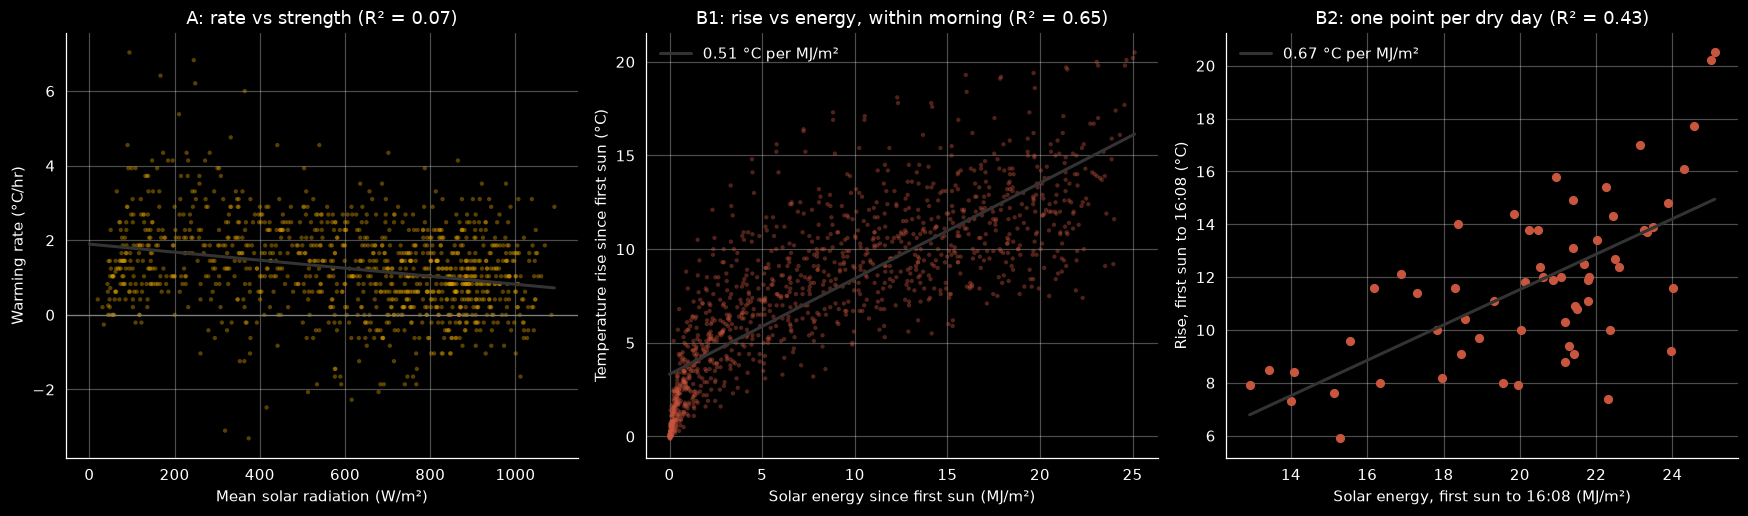

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

ax = axes[0]
ax.scatter(blocks_A["solar"], blocks_A["rate"], s=8, alpha=0.4, color=SOLAR_COLOR, edgecolor="none")
xs = np.linspace(0, blocks_A["solar"].max(), 50)
ax.plot(xs, fitA.slope * xs + fitA.intercept, color=DARK, lw=2)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("Mean solar radiation (W/m²)"); ax.set_ylabel("Warming rate (°C/hr)")
ax.set_title(f"A: rate vs strength (R² = {fitA.rvalue**2:.2f})")

ax = axes[1]
ax.scatter(samples_B["energy_MJ_m2"], samples_B["rise_C"], s=8, alpha=0.4, color=TEMP_COLOR, edgecolor="none")
xs = np.linspace(0, samples_B["energy_MJ_m2"].max(), 50)
ax.plot(xs, fitB.slope * xs + fitB.intercept, color=DARK, lw=2, label=f"{fitB.slope:.2f} °C per MJ/m²")
ax.set_xlabel("Solar energy since first sun (MJ/m²)"); ax.set_ylabel("Temperature rise since first sun (°C)")
ax.set_title(f"B1: rise vs energy, within morning (R² = {fitB.rvalue**2:.2f})"); ax.legend(frameon=False)

ax = axes[2]
ax.scatter(per_day["energy_MJ_m2"], per_day["rise_C"], s=25, color=TEMP_COLOR)
if fitB2:
    xs = np.linspace(per_day["energy_MJ_m2"].min(), per_day["energy_MJ_m2"].max(), 50)
    ax.plot(xs, fitB2.slope * xs + fitB2.intercept, color=DARK, lw=2, label=f"{fitB2.slope:.2f} °C per MJ/m²")
    ax.legend(frameon=False)
    ax.set_title(f"B2: one point per dry day (R² = {fitB2.rvalue**2:.2f})")
ax.set_xlabel(f"Solar energy, first sun to {cutoff_str} (MJ/m²)"); ax.set_ylabel(f"Rise, first sun to {cutoff_str} (°C)")

fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "sun_warming_fits.png"), dpi=200, bbox_inches="tight")
plt.show()

## 6b. Log fit: rise vs energy

The straight line in B1 misses a clear bend: the first MJ/m² after sunrise warms the air much more than later ones. A log curve fits that shape:

`rise (°C) = a × ln(1 + energy / b)`

- `a` sets how tall the curve is
- `b` (MJ/m²) sets where it bends. Below `b` the rise is close to a straight line; above `b` each extra MJ/m² adds less
- Extra warming from one more MJ/m² at a given energy level is `a / (b + energy)`

The right panel plots the same points against `ln(1 + energy / b)`, where a log relationship becomes a straight line.

Log fit:    rise (°C) = 3.53 × ln(1 + energy / 0.65)   R² = 0.740
Linear fit: rise (°C) = 0.510 × energy +3.32       R² = 0.652


,energy_MJ_m2,predicted_rise_C,extra_C_per_extra_MJ
0,0,0.00,5.43
1,1,3.29,2.14
2,2,4.96,1.33
3,5,7.63,0.63
4,10,9.87,0.33
5,15,11.23,0.23
6,20,12.21,0.17
7,25,12.98,0.14


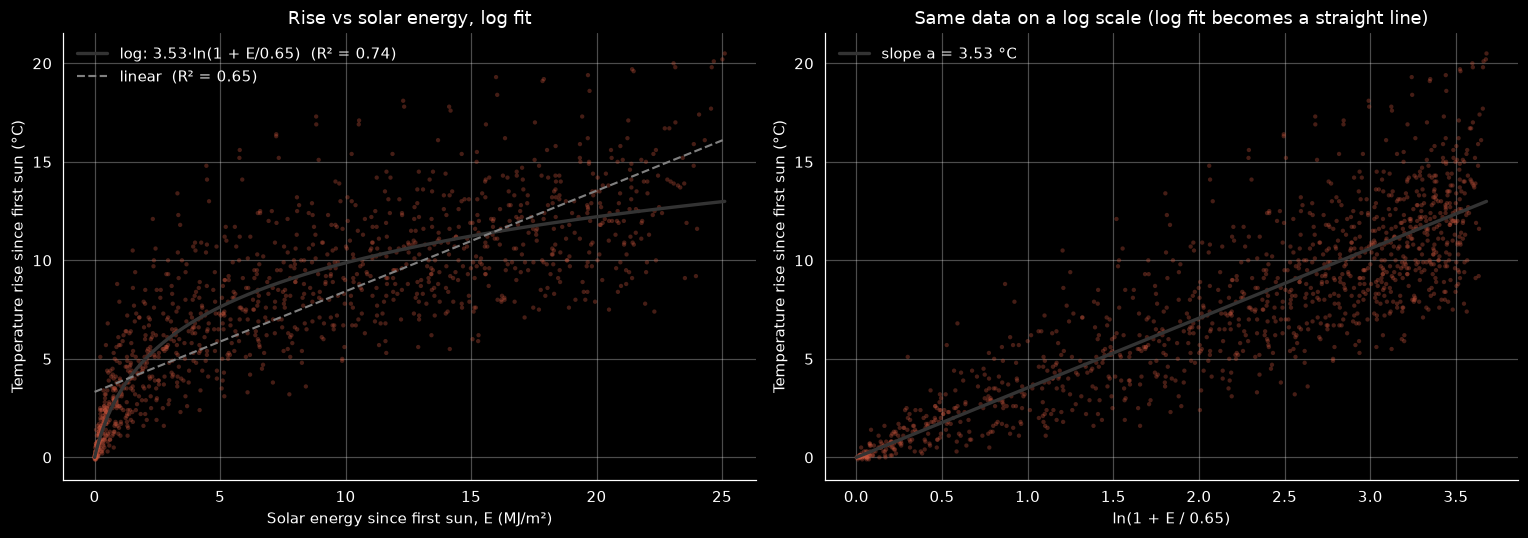

In [8]:
from scipy.optimize import curve_fit

def log_model(E, a, b):
    return a * np.log1p(E / b)

E_B, R_B = samples_B["energy_MJ_m2"].values, samples_B["rise_C"].values
(log_a, log_b), _ = curve_fit(log_model, E_B, R_B, p0=[4, 1], bounds=([0, 1e-3], [100, 100]))
pred_log = log_model(E_B, log_a, log_b)
r2_log = 1 - np.sum((R_B - pred_log) ** 2) / np.sum((R_B - R_B.mean()) ** 2)

print(f"Log fit:    rise (°C) = {log_a:.2f} × ln(1 + energy / {log_b:.2f})   R² = {r2_log:.3f}")
print(f"Linear fit: rise (°C) = {fitB.slope:.3f} × energy {fitB.intercept:+.2f}       R² = {fitB.rvalue**2:.3f}")
marginal = pd.DataFrame({"energy_MJ_m2": [0, 1, 2, 5, 10, 15, 20, 25]})
marginal["predicted_rise_C"] = log_model(marginal["energy_MJ_m2"], log_a, log_b)
marginal["extra_C_per_extra_MJ"] = log_a / (log_b + marginal["energy_MJ_m2"])
display(marginal.round(2))

def predict_rise_log(energy_MJ_m2):
    # predicted outdoor temperature rise (°C) since first sun for a given energy since first sun
    return log_model(np.asarray(energy_MJ_m2, dtype=float), log_a, log_b)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.scatter(E_B, R_B, s=8, alpha=0.35, color=TEMP_COLOR, edgecolor="none")
xs = np.linspace(0, E_B.max(), 300)
ax1.plot(xs, log_model(xs, log_a, log_b), color=DARK, lw=2.2,
         label=f"log: {log_a:.2f}·ln(1 + E/{log_b:.2f})  (R² = {r2_log:.2f})")
ax1.plot(xs, fitB.slope * xs + fitB.intercept, color="grey", lw=1.4, ls="--",
         label=f"linear  (R² = {fitB.rvalue**2:.2f})")
ax1.set_xlabel("Solar energy since first sun, E (MJ/m²)")
ax1.set_ylabel("Temperature rise since first sun (°C)")
ax1.set_title("Rise vs solar energy, log fit")
ax1.legend(frameon=False, loc="upper left")

xl = np.log1p(E_B / log_b)
ax2.scatter(xl, R_B, s=8, alpha=0.35, color=TEMP_COLOR, edgecolor="none")
xx = np.linspace(0, xl.max(), 100)
ax2.plot(xx, log_a * xx, color=DARK, lw=2.2, label=f"slope a = {log_a:.2f} °C")
ax2.set_xlabel(f"ln(1 + E / {log_b:.2f})")
ax2.set_ylabel("Temperature rise since first sun (°C)")
ax2.set_title("Same data on a log scale (log fit becomes a straight line)")
ax2.legend(frameon=False, loc="upper left")

fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "sun_warming_log_fit.png"), dpi=200, bbox_inches="tight")
plt.show()

## 7. Save results

In [9]:
from openpyxl.styles import Font, PatternFill

def row(name, f, x, y, n):
    return {"fit": name, "x": x, "y": y, "slope": f.slope, "intercept": f.intercept,
            "R2": f.rvalue ** 2, "p_value": f.pvalue, "n": n}

summary = pd.DataFrame([
    row("A: rate vs strength", fitA, "solar (W/m2)", "warming rate (C/hr)", len(blocks_A)),
    row("B1: rise vs energy, within morning", fitB, "energy since first sun (MJ/m2)", "rise since first sun (C)", len(samples_B)),
] + [{"fit": "B1 log: rise = a*ln(1 + E/b)", "x": "energy since first sun (MJ/m2)", "y": "rise since first sun (C)",
       "slope": log_a, "intercept": log_b, "R2": r2_log, "p_value": np.nan, "n": len(samples_B)}] + ([row("B2: rise vs energy, one per day", fitB2, f"energy to {cutoff_str} (MJ/m2)", f"rise to {cutoff_str} (C)", len(per_day))] if fitB2 else []))
settings = pd.DataFrame({"setting": ["cutoff time", "dry days used", "rain days removed", "block", "first-sun threshold (W/m2)"],
                         "value": [cutoff_str, warm["date"].nunique(), len(all_days) - len(dry_days), BLOCK, SOLAR_START]})

sheets = {
    "Summary": ("Linear fits for how much the sun warms outdoor air. Rain days removed, data from first sun to the cutoff only.", summary),
    "Settings": ("Settings used for this run.", settings),
    "Per day": (f"One row per dry day: solar energy and temperature rise from first sun to {cutoff_str}.", per_day.reset_index()),
    "Log fit marginal": ("Log fit: predicted rise and extra warming from one more MJ/m2 at each energy level. "
                         "For the log row in Summary, slope = a and intercept = b.", marginal),
    "Rate blocks (A)": (f"Each {BLOCK} block used in Fit A.", blocks_A.reset_index()),
}
xlsx = os.path.join(OUT_DIR, "sun_warming_results.xlsx")
with pd.ExcelWriter(xlsx, engine="openpyxl") as xw:
    for name, (desc, t) in sheets.items():
        t = t.copy()
        for c in t.columns:
            if t[c].dtype.kind == "f" and c != "p_value":
                t[c] = t[c].round(5)
        t.to_excel(xw, sheet_name=name, index=False, startrow=3)
        ws = xw.sheets[name]
        ws["A1"] = name; ws["A1"].font = Font(name="Arial", size=12, bold=True)
        ws["A2"] = desc; ws["A2"].font = Font(name="Arial", size=10, italic=True, color="555555")
        for r in ws.iter_rows(min_row=4):
            for cell in r:
                cell.font = Font(name="Arial", size=10, bold=cell.row == 4)
                if cell.row == 4:
                    cell.fill = PatternFill("solid", fgColor="DCE6F1")
                elif hasattr(cell.value, "hour"):
                    cell.number_format = "yyyy-mm-dd hh:mm"
        for i, col in enumerate(t.columns, 1):
            ws.column_dimensions[ws.cell(row=4, column=i).column_letter].width = min(max(len(str(col)) + 2, 12), 36)
        ws.freeze_panes = "A5"

print("Saved to", os.path.abspath(OUT_DIR))
for f in sorted(os.listdir(OUT_DIR)):
    print("  ", f)

Saved to /home/biceplover/IRES_AUSTRIA/senior_design/output/sun_warming
   average_day_cutoff.png
   sun_warming_fits.png
   sun_warming_log_fit.png
   sun_warming_results.xlsx
